# Double Exponential Transport

This notebook builds a transport map between all discussed combination in Appendix B (in J_Marghi_OMT_TMLR_2026.pdf) using:

- Using \($T(x)=F_t^{-1}(F_s(x))$\)
- Eq. 118, 120, 123, and 124 style explicit form for the four-parameter case

Each double-exponential law is parameterized by 4 values:

- `w`: component weight/mass
- `c` & `d`: rate parameter
- `b`: location/shift

The class below provides:

- `map(x)`: transport map from source to target
- `plot(...)`: coupling map with source marginal on the left and target marginal on the top

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf, erfinv
from matplotlib.gridspec import GridSpec
from scipy.stats import norm, gaussian_kde
from scipy.signal import argrelextrema
from scipy.special import logsumexp
import matplotlib.pyplot as plt

from exp_functions import GaussianLike, DoubleExponential, em_mixture, plot_mixture, plot_omt_coupling, plot_omt_coupling_nd
from general_solver import omt

%load_ext autoreload
%autoreload 2

### Examples for each group

Fitting K=2, N=10000, D=1


  Cluster 1 (n=7411): sumBIC(G)=19251.0  sumBIC(A)=20007.2
  Cluster 2 (n=2589): sumBIC(G)=2990.9  sumBIC(A)=3231.9
  EM done: 2G+0A  BIC=33974.6
  Checking type swaps...

─── Result: 2 Gaussian + 0 Exp  BIC=33974.6 ───
  Gaussian 1: w=0.741  b=0.861  c=1.768(1/c=0.565)  d=0.513(1/d=1.949)
  Gaussian 2: w=0.259  b=6.266  c=1.167(1/c=0.857)  d=2.445(1/d=0.409)

─── Final 1-D Parameters ───
  Gaussian 1: w=0.741  b=0.861  c=1.768  d=0.513
  Gaussian 2: w=0.259  b=6.266  c=1.167  d=2.445


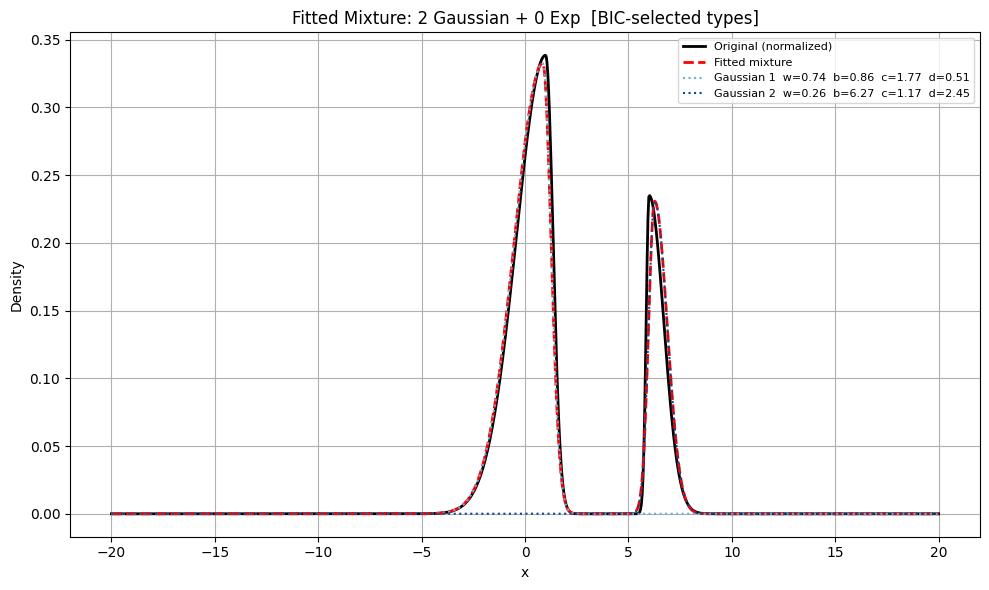

In [ ]:
# ── 1-D test ──
src_g = [GaussianLike(b=1, c=2.0, d=.5), GaussianLike(b=6, c=1, d=5)]
x = np.linspace(-20, 20, 1000)
a = .75 
pdf_x = a * src_g[0].pdf(x) + (1 - a) * src_g[1].pdf(x)
y = pdf_x / pdf_x.sum()

source_samples = np.random.choice(x, size=10000, p=y)

params_s = em_mixture(source_samples, K=2, n_iter=100, bw=0.1)
print("\n─── Final 1-D Parameters ───")
for k in range(params_s['K']):
    t = params_s['types'][k]
    w = params_s['weights'][k]
    cr = params_s['c_rates'][k, 0]; dr = params_s['d_rates'][k, 0]
    print(f"  {t} {k+1}: w={w:.3f}  b={params_s['means'][k,0]:.3f}"
            f"  c={cr:.3f}  d={dr:.3f}")

plot_mixture(x, y, params_s)

Fitting K=2, N=10000, D=1


  Cluster 1 (n=3710): sumBIC(G)=6173.9  sumBIC(A)=5549.2
  Cluster 2 (n=6290): sumBIC(G)=16849.9  sumBIC(A)=17754.5
  EM done: 1G+1A  BIC=34736.4
  Checking type swaps...


    Swap comp 1 A→G: BIC 34736.4 → 34559.8



─── Result: 2 Gaussian + 0 Exp  BIC=34559.8 ───
  Gaussian 1: w=0.341  b=0.941  c=1.883(1/c=0.531)  d=2.107(1/d=0.475)
  Gaussian 2: w=0.659  b=5.866  c=0.958(1/c=1.044)  d=0.526(1/d=1.903)

─── Final 1-D Parameters ───
  Gaussian 1: w=0.341  b=0.941  c=1.883  d=2.107
  Gaussian 2: w=0.659  b=5.866  c=0.958  d=0.526


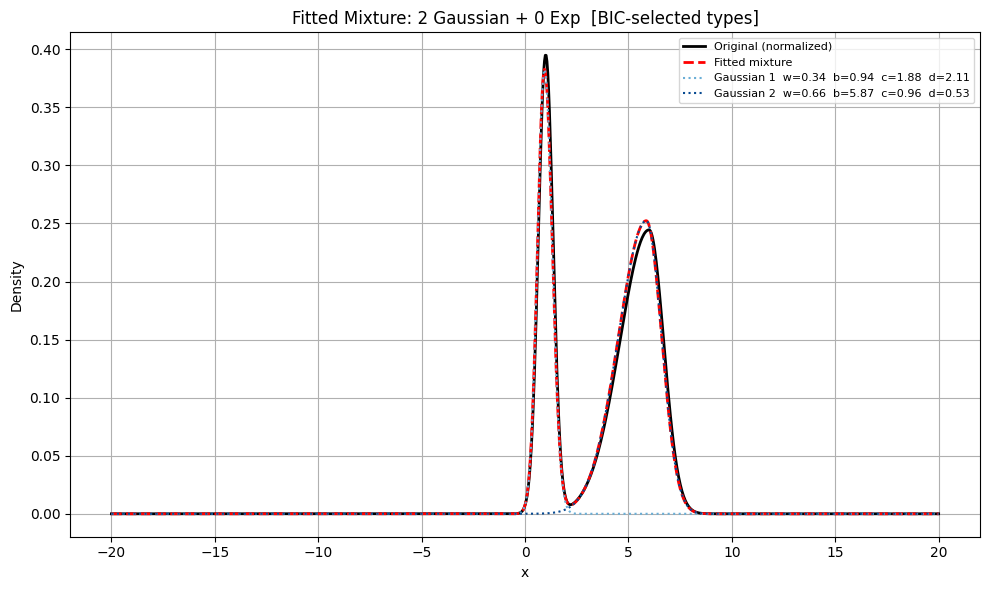

In [ ]:
tgt_g = [GaussianLike(b=1, c=2.0, d=2.0), GaussianLike(b=6, c=1, d=0.5)]
a = .35
x = np.linspace(-20, 20, 1000)
pdf_x = a * tgt_g[0].pdf(x) + (1 - a) * tgt_g[1].pdf(x)
y = pdf_x / (pdf_x.sum())
target_samples = np.random.choice(x, size=10000, p=y)

params_t = em_mixture(target_samples, K=2, n_iter=100, bw=0.1)
print("\n─── Final 1-D Parameters ───")
for k in range(params_t['K']):
    t = params_t['types'][k]
    w = params_t['weights'][k]
    cr = params_t['c_rates'][k, 0]; dr = params_t['d_rates'][k, 0]
    print(f"  {t} {k+1}: w={w:.3f}  b={params_t['means'][k,0]:.3f}"
            f"  c={cr:.3f}  d={dr:.3f}")

plot_mixture(x, y, params_t)

### Compare `fitting_mode`: `mix`, `gauss`, `exp`

Each mode fits source/target with a different family, then solves the optimal transport.  
Coupling plots show the joint density $\pi(x,y)$ with marginals.

In [ ]:
results = {}
for mode in ['mix', 'gauss', 'exp']:
    kw = dict(data_source=source_samples, data_target=target_samples,
              n_components=(2, 2), eps_gmm=.1, eps_w=.1,
              fitting_mode=mode, method='cvx',
              max_iter=10000, stop_thr=1e-6, verbose=True)
    if mode == 'gauss':
        kw['cov_type'] = 'diag'
    w, sd = omt(**kw)
    results[mode] = (w, sd)
    print()

Fitting K=2, N=10000, D=1


  Cluster 1 (n=7411): sumBIC(G)=19251.0  sumBIC(A)=20007.2
  Cluster 2 (n=2589): sumBIC(G)=2990.9  sumBIC(A)=3231.9
  EM done: 2G+0A  BIC=33974.6
  Checking type swaps...

─── Result: 2 Gaussian + 0 Exp  BIC=33974.6 ───
  Gaussian 1: w=0.741  b=0.861  c=1.768(1/c=0.565)  d=0.513(1/d=1.949)
  Gaussian 2: w=0.259  b=6.266  c=1.167(1/c=0.857)  d=2.445(1/d=0.409)
Fitting K=2, N=10000, D=1


  Cluster 1 (n=3690): sumBIC(G)=5952.0  sumBIC(A)=5363.5
  Cluster 2 (n=6310): sumBIC(G)=16979.6  sumBIC(A)=17876.5
  EM done: 1G+1A  BIC=34736.4
  Checking type swaps...


    Swap comp 1 A→G: BIC 34736.4 → 34559.8



─── Result: 2 Gaussian + 0 Exp  BIC=34559.8 ───
  Gaussian 1: w=0.341  b=0.941  c=1.883(1/c=0.531)  d=2.107(1/d=0.475)
  Gaussian 2: w=0.659  b=5.866  c=0.958(1/c=1.044)  d=0.526(1/d=1.903)
Number of components in source: 2
Number of components in target: 2
Fitting mode: mix
Time taken for fitting: 3.0014097690582275 seconds
Total transportation cost: 47.40366523076947
Discrepence in marginals' weights: 1.311095594265837e-07 1.1656952885979221e-07
Number of iterations: 675
Time taken for transportation optimzation: 0.020261764526367188 seconds
Number of total iterations: 20675
Total time taken: 3.0216715335845947 seconds



Fitted a GMM with 2 components.
Model converged: True
Number of iterations: 2
--------------------------------------------------
Fitted a GMM with 2 components.
Model converged: True
Number of iterations: 4
--------------------------------------------------
Number of components in source: 2
Number of components in target: 2
Fitting mode: gauss
Time taken for fitting: 0.355074405670166 seconds
Total transportation cost: 50.93544236768469
Discrepence in marginals' weights: 7.688118658423121e-11 6.573321610908638e-11
Number of iterations: 650
Time taken for transportation optimzation: 0.01785111427307129 seconds
Number of total iterations: 656
Total time taken: 0.3729255199432373 seconds

Fitting Exp-only K=2, N=10000, D=1


  EM done: 2A  BIC=34691.4

─── Result: 0 Gaussian + 2 Exp  BIC=34691.4 ───
  Exp 1: w=0.741  b=0.981  c=3.487(1/c=0.287)  d=0.885(1/d=1.129)
  Exp 2: w=0.259  b=5.946  c=1.685(1/c=0.593)  d=11.078(1/d=0.090)
Fitting Exp-only K=2, N=10000, D=1


  EM done: 2A  BIC=35210.0

─── Result: 0 Gaussian + 2 Exp  BIC=35210.0 ───
  Exp 1: w=0.331  b=0.981  c=3.397(1/c=0.294)  d=3.775(1/d=0.265)
  Exp 2: w=0.669  b=6.106  c=1.978(1/c=0.506)  d=0.809(1/d=1.236)
Number of components in source: 2
Number of components in target: 2
Fitting mode: exp
Time taken for fitting: 2.5592522621154785 seconds
Total transportation cost: 50.34159809785074
Discrepence in marginals' weights: 3.110010488197006e-10 2.555827906420636e-10
Number of iterations: 725
Time taken for transportation optimzation: 0.011215925216674805 seconds
Number of total iterations: 20725
Total time taken: 2.5704681873321533 seconds



In [ ]:
print("="*60)
print("Summary")
print("="*60)
for mode, (w, sd) in results.items():
    print(f"  {mode:12s}  cost={sd['total_cost']:.4f}  time={sd['time']:.3f}s  iters={sd['n_total_iter']}")

Summary
  mix           cost=47.4037  time=3.022s  iters=20675
  gauss         cost=50.9354  time=0.373s  iters=656
  exp           cost=50.3416  time=2.570s  iters=20725


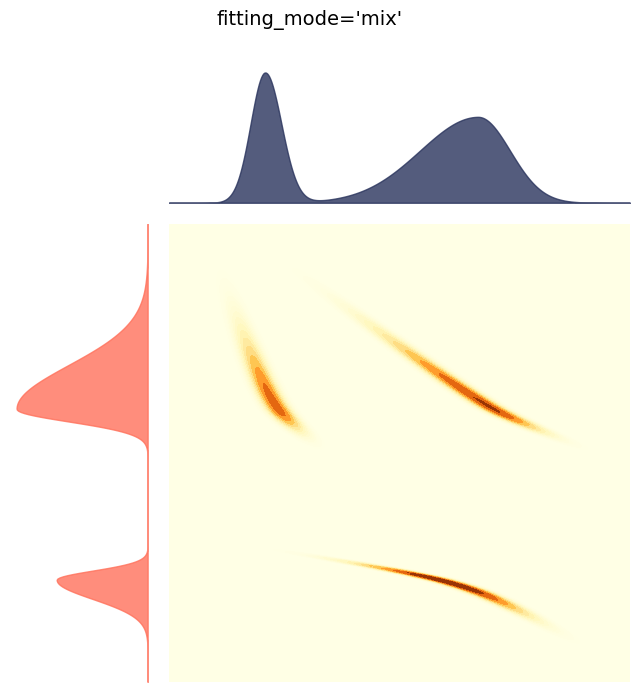

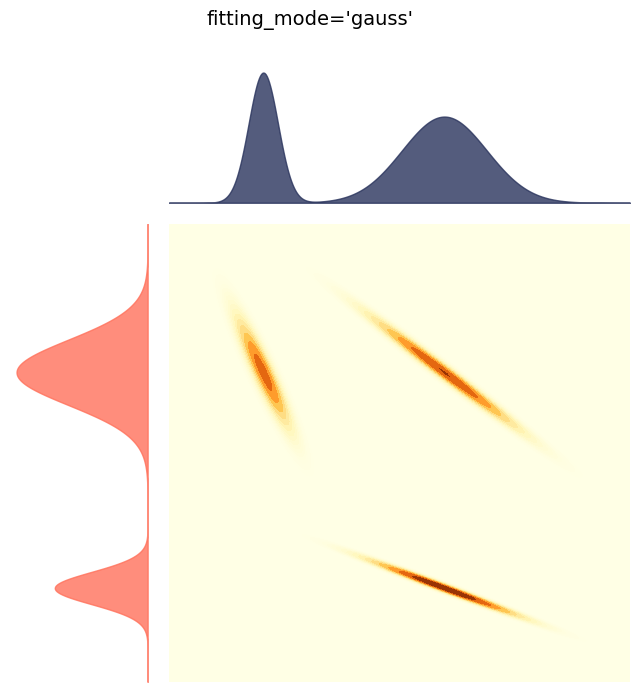

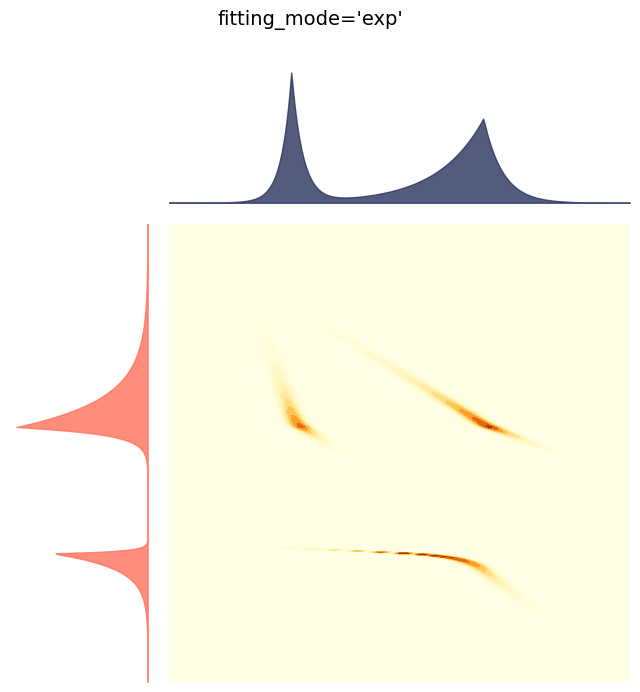

In [ ]:
def build_pdf_list(mm):
    """Build list of distribution objects from a fitted mixture dict."""
    comps = []
    for k in range(mm['K']):
        t = mm['types'][k]
        if t == 'Gaussian':
            comps.append(GaussianLike(b=mm['means'][k], c=mm['c_rates'][k], d=mm['d_rates'][k]))
        else:
            comps.append(DoubleExponential(b=mm['means'][k], c=mm['c_rates'][k], d=mm['d_rates'][k]))
    return comps

for mode, (w, sd) in results.items():
    src_comps = build_pdf_list(sd['mm_s'])
    tgt_comps = build_pdf_list(sd['mm_t'])
    plot_omt_coupling(src_comps, tgt_comps, w,
                      title=f"fitting_mode='{mode}'", eps=.15)

Fitting K=2, N=10000, D=1


  Cluster 1 (n=3134): sumBIC(G)=6833.6  sumBIC(A)=7144.0
  Cluster 2 (n=6866): sumBIC(G)=34221.6  sumBIC(A)=34230.4
  EM done: 2G+0A  BIC=53484.8
  Checking type swaps...

─── Result: 2 Gaussian + 0 Exp  BIC=53484.8 ───
  Gaussian 1: w=0.314  b=0.981  c=0.965(1/c=1.036)  d=0.996(1/d=1.004)
  Gaussian 2: w=0.686  b=5.065  c=0.128(1/c=7.807)  d=2.396(1/d=0.417)

─── Final 1-D Parameters ───
  Gaussian 1: w=0.314  b=0.981  c=0.965  d=0.996
  Gaussian 2: w=0.686  b=5.065  c=0.128  d=2.396


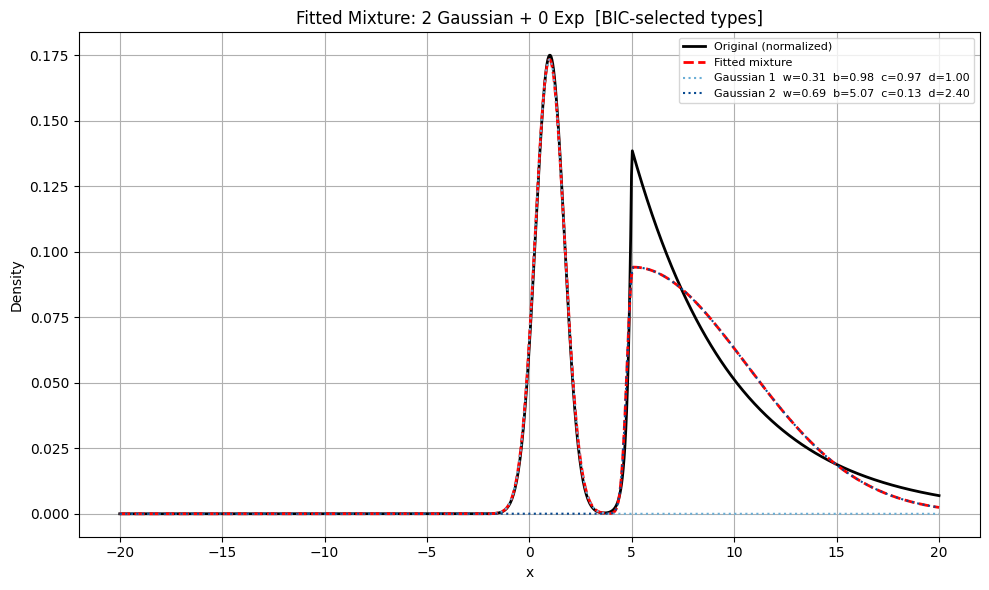

In [ ]:
# ── 1-D test ──
# Case 3: Mixed 
src_g = [GaussianLike(b=1, c=1, d=1), DoubleExponential(b=5, c=.2, d=5)]
x = np.linspace(-20, 20, 1000)
a = .3
pdf_x = a * src_g[0].pdf(x) + (1 - a) * src_g[1].pdf(x)
y = pdf_x / pdf_x.sum()

source_samples = np.random.choice(x, size=10000, p=y)

params_s = em_mixture(source_samples, K=len(src_g), n_iter=100, bw=0.1)
print("\n─── Final 1-D Parameters ───")
for k in range(params_s['K']):
    t = params_s['types'][k]
    w = params_s['weights'][k]
    cr = params_s['c_rates'][k, 0]; dr = params_s['d_rates'][k, 0]
    print(f"  {t} {k+1}: w={w:.3f}  b={params_s['means'][k,0]:.3f}"
            f"  c={cr:.3f}  d={dr:.3f}")

plot_mixture(x, y, params_s)

Fitting K=2, N=10000, D=1


  Cluster 1 (n=5075): sumBIC(G)=9005.2  sumBIC(A)=8240.0
  Cluster 2 (n=4925): sumBIC(G)=8653.3  sumBIC(A)=9152.6
  EM done: 1G+1A  BIC=30839.2
  Checking type swaps...

─── Result: 1 Gaussian + 1 Exp  BIC=30839.2 ───
  Exp 1: w=0.508  b=-4.985  c=2.040(1/c=0.490)  d=2.975(1/d=0.336)
  Gaussian 2: w=0.492  b=4.825  c=1.311(1/c=0.763)  d=1.120(1/d=0.893)

─── Final 1-D Parameters ───
  Exp 1: w=0.508  b=-4.985  c=2.040  d=2.975
  Gaussian 2: w=0.492  b=4.825  c=1.311  d=1.120


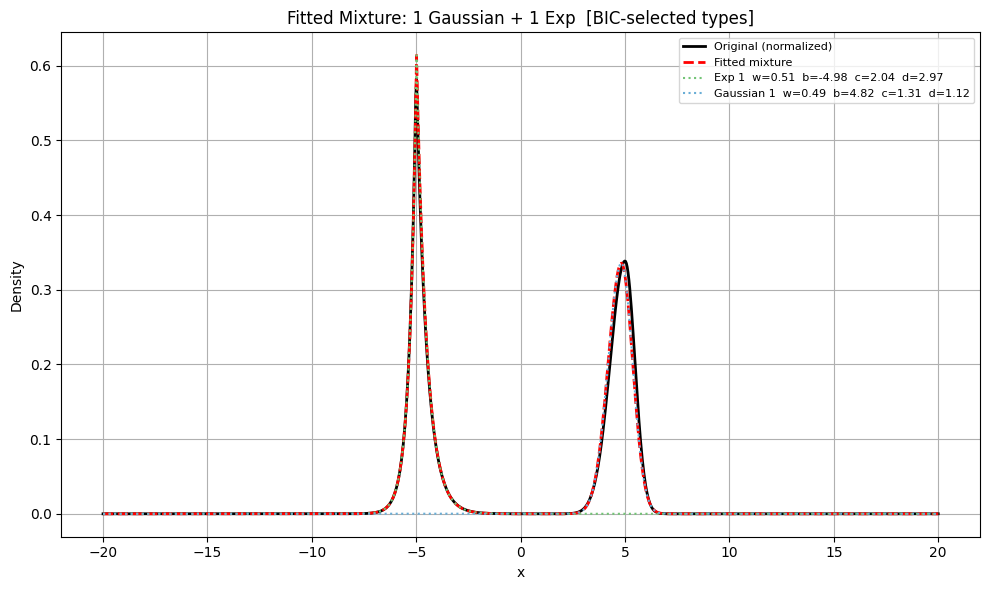

In [ ]:
tgt_g = [DoubleExponential(b=-5, c=2, d=3), GaussianLike(b=5, c=1.5, d=1)]
a = .5
x = np.linspace(-20, 20, 1000)
pdf_x = a * tgt_g[0].pdf(x) + (1 - a) * tgt_g[1].pdf(x)
y = pdf_x / (pdf_x.sum())
target_samples = np.random.choice(x, size=10000, p=y)

params_t = em_mixture(target_samples, K=len(tgt_g), n_iter=100, bw=0.1)
print("\n─── Final 1-D Parameters ───")
for k in range(params_t['K']):
    t = params_t['types'][k]
    w = params_t['weights'][k]
    cr = params_t['c_rates'][k, 0]; dr = params_t['d_rates'][k, 0]
    print(f"  {t} {k+1}: w={w:.3f}  b={params_t['means'][k,0]:.3f}"
            f"  c={cr:.3f}  d={dr:.3f}")

plot_mixture(x, y, params_t)

In [ ]:
omt_w, solver_dict = omt(
                        data_source=source_samples, 
                        data_target=target_samples, 
                        n_components=(2, 2), 
                        eps_gmm=.05, 
                        eps_w=.05, 
                        fitting_mode='mix',
                        method='cvx', 
                        max_iter=10000,
                        stop_thr=1e-6,
                        verbose=True)

Fitting K=2, N=10000, D=1


  Cluster 1 (n=3134): sumBIC(G)=6833.6  sumBIC(A)=7144.0
  Cluster 2 (n=6866): sumBIC(G)=34221.6  sumBIC(A)=34230.4
  EM done: 2G+0A  BIC=53484.8
  Checking type swaps...

─── Result: 2 Gaussian + 0 Exp  BIC=53484.8 ───
  Gaussian 1: w=0.314  b=0.981  c=0.965(1/c=1.036)  d=0.996(1/d=1.004)
  Gaussian 2: w=0.686  b=5.065  c=0.128(1/c=7.807)  d=2.396(1/d=0.417)
Fitting K=2, N=10000, D=1


  Cluster 1 (n=5075): sumBIC(G)=9005.2  sumBIC(A)=8240.0
  Cluster 2 (n=4925): sumBIC(G)=8653.3  sumBIC(A)=9152.6
  EM done: 1G+1A  BIC=30839.2
  Checking type swaps...

─── Result: 1 Gaussian + 1 Exp  BIC=30839.2 ───
  Exp 1: w=0.508  b=-4.985  c=2.040(1/c=0.490)  d=2.975(1/d=0.336)
  Gaussian 2: w=0.492  b=4.825  c=1.311(1/c=0.763)  d=1.120(1/d=0.893)
Number of components in source: 2
Number of components in target: 2
Fitting mode: mix
Time taken for fitting: 2.6834142208099365 seconds
Total transportation cost: 195.72175543477763
Discrepence in marginals' weights: 2.9933422077859178e-12 2.2066079414341777e-12
Number of iterations: 8950
Time taken for transportation optimzation: 0.02553701400756836 seconds
Number of total iterations: 28950
Total time taken: 2.708951234817505 seconds
